# Bird species classification: autoencoder + linear probe

1. Train a convolutional autoencoder on the 4800 unlabelled clips.
2. Use the encoder to turn each labelled clip into an embedding.
3. Train a linear classifier on those embeddings using the 100 labelled clips.
4. Predict the species of the 100 test clips.

In [20]:
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from pathlib import Path
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

DATA_DIR = Path("data")
SR = 32000
N_MELS = 64
N_FRAMES = 312

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

## Loading the data

Each clip is turned into a log-mel spectrogram of shape (64 mel bands × 312 time frames), scaled to lie between 0 and 1.

In [21]:
AUDIO_EXTS = {".wav", ".flac", ".ogg", ".mp3"}


def load_mel(path):
    y, _ = librosa.load(path, sr=SR, duration=5.0)
    y = np.pad(y, (0, max(0, 5 * SR - len(y))))
    mel = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=1024, hop_length=512, n_mels=N_MELS, fmin=50, fmax=14000)
    mel = librosa.power_to_db(mel, ref=np.max, top_db=80)
    return (mel[:, :N_FRAMES] / 80 + 1).astype(np.float32)


def load_files(paths):
    return np.stack(Parallel(n_jobs=8)(delayed(load_mel)(p) for p in paths))


def audio_files(folder):
    return sorted(p for p in folder.iterdir() if p.suffix.lower() in AUDIO_EXTS)

Computing spectrograms for 4800 clips takes a few minutes, so we save them to `cache/` the first time.

In [22]:
cache = Path("cache/unlabelled.npy")
if cache.exists():
    X_unlab = np.load(cache)
else:
    X_unlab = load_files(audio_files(DATA_DIR / "unlabelled"))
    cache.parent.mkdir(exist_ok=True)
    np.save(cache, X_unlab)

X_unlab.shape

(4800, 64, 312)

In [23]:
labels = pd.read_csv(DATA_DIR / "labelled" / "labels.csv")
classes = sorted(labels.species.unique())
X_lab = load_files([DATA_DIR / "labelled" / f for f in labels.filename])
y_lab = labels.species.map({c: i for i, c in enumerate(classes)}).values

print(X_lab.shape)
labels.species.value_counts()

(100, 64, 312)


species
Eurasian Wren     66
Song Thrush       19
European Robin    15
Name: count, dtype: int64

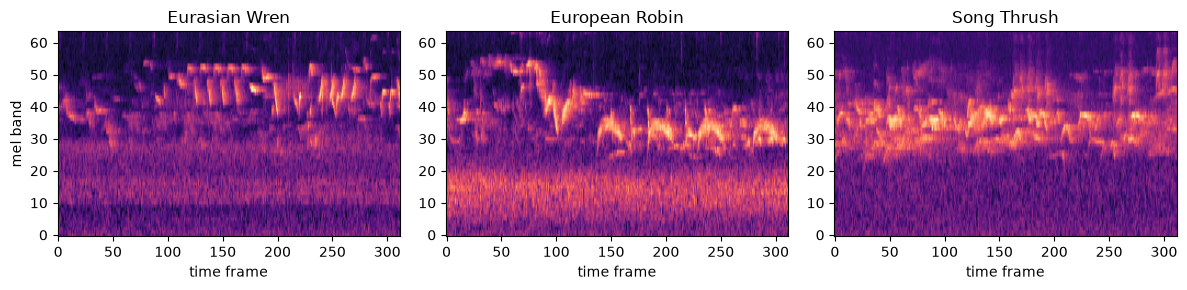

In [24]:
fig, axes = plt.subplots(1, len(classes), figsize=(4 * len(classes), 3))
for ax, c in zip(axes, range(len(classes))):
    ax.imshow(X_lab[y_lab == c][0], origin="lower", aspect="auto", cmap="magma")
    ax.set_title(classes[c])
    ax.set_xlabel("time frame")
axes[0].set_ylabel("mel band")
plt.tight_layout()

## Autoencoder

The encoder squeezes each 64 × 312 spectrogram down to a 128-dimensional embedding, and the decoder tries to rebuild the spectrogram from it.

In [25]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),   # 16 x 32 x 156
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),  # 32 x 16 x 78
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),  # 64 x 8 x 39
            nn.Flatten(),
            nn.Linear(64 * 8 * 39, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64 * 8 * 39), nn.ReLU(),
            nn.Unflatten(1, (64, 8, 39)),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1), nn.Sigmoid(),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


ae = Autoencoder().to(device)
sum(p.numel() for p in ae.parameters())

5178433

In [26]:
unlab_loader = DataLoader(TensorDataset(torch.tensor(X_unlab).unsqueeze(1)), batch_size=64, shuffle=True)

optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
n_epochs = 20

ae_losses = []
for epoch in range(n_epochs):
    ae.train()
    total = 0
    for (xb,) in unlab_loader:
        xb = xb.to(device)
        loss = loss_fn(ae(xb), xb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
    ae_losses.append(total / len(unlab_loader.dataset))
    print(f"epoch {epoch + 1}: reconstruction loss {ae_losses[-1]:.4f}")

epoch 1: reconstruction loss 0.0115
epoch 2: reconstruction loss 0.0039
epoch 3: reconstruction loss 0.0033
epoch 4: reconstruction loss 0.0025
epoch 5: reconstruction loss 0.0024
epoch 6: reconstruction loss 0.0023
epoch 7: reconstruction loss 0.0022
epoch 8: reconstruction loss 0.0021
epoch 9: reconstruction loss 0.0021
epoch 10: reconstruction loss 0.0021
epoch 11: reconstruction loss 0.0020
epoch 12: reconstruction loss 0.0020
epoch 13: reconstruction loss 0.0020
epoch 14: reconstruction loss 0.0020
epoch 15: reconstruction loss 0.0019
epoch 16: reconstruction loss 0.0019
epoch 17: reconstruction loss 0.0019
epoch 18: reconstruction loss 0.0019
epoch 19: reconstruction loss 0.0019
epoch 20: reconstruction loss 0.0018


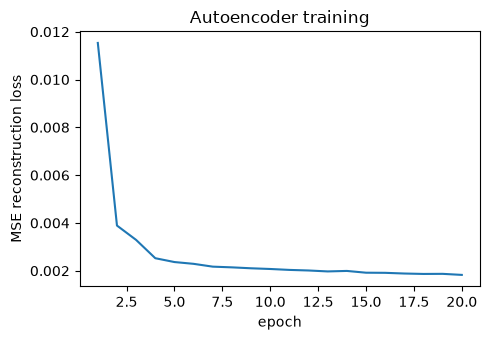

In [27]:
plt.figure(figsize=(5, 3.5))
plt.plot(range(1, n_epochs + 1), ae_losses)
plt.xlabel("epoch")
plt.ylabel("MSE reconstruction loss")
plt.title("Autoencoder training")
plt.tight_layout()

### Reconstructions

Five random unlabelled clips (top) and what the autoencoder rebuilds from their embeddings (bottom).

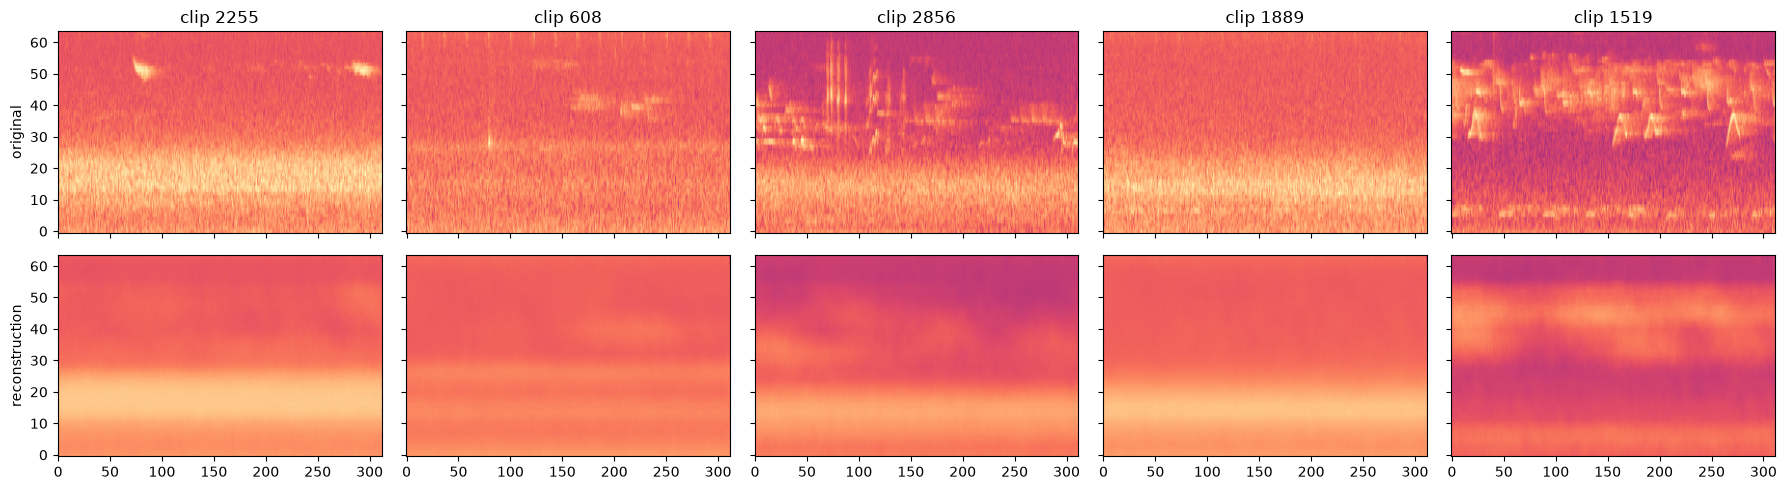

In [28]:
idx = np.random.choice(len(X_unlab), 5, replace=False)
ae.eval()
with torch.no_grad():
    recon = ae(torch.tensor(X_unlab[idx]).unsqueeze(1).to(device)).squeeze(1).cpu().numpy()

fig, axes = plt.subplots(2, 5, figsize=(18, 5), sharex=True, sharey=True)
for j, i in enumerate(idx):
    axes[0, j].imshow(X_unlab[i], origin="lower", aspect="auto", cmap="magma", vmin=0, vmax=1)
    axes[1, j].imshow(recon[j], origin="lower", aspect="auto", cmap="magma", vmin=0, vmax=1)
    axes[0, j].set_title(f"clip {i}")
axes[0, 0].set_ylabel("original")
axes[1, 0].set_ylabel("reconstruction")
plt.tight_layout()

In [29]:
from IPython.display import Audio, display


def mel_to_audio(mel):
    # Undo the scaling from load_mel (back to dB, then power) and invert with Griffin-Lim
    power = librosa.db_to_power((mel - 1) * 80)
    return librosa.feature.inverse.mel_to_audio(power, sr=SR, n_fft=1024, hop_length=512, fmin=50, fmax=14000)


unlab_paths = audio_files(DATA_DIR / "unlabelled")  # same order as X_unlab

# Phase is lost in a spectrogram, so the last two are approximate and sound a little metallic
for j, i in enumerate(idx):
    print(f"clip {i}: raw audio, original spectrogram, reconstruction")
    display(Audio(librosa.load(unlab_paths[i], sr=SR, duration=5.0)[0], rate=SR))
    display(Audio(mel_to_audio(X_unlab[i]), rate=SR))
    display(Audio(mel_to_audio(recon[j]), rate=SR))

clip 2255: raw audio, original spectrogram, reconstruction


clip 608: raw audio, original spectrogram, reconstruction


clip 2856: raw audio, original spectrogram, reconstruction


clip 1889: raw audio, original spectrogram, reconstruction


clip 1519: raw audio, original spectrogram, reconstruction


## Linear probe

Freeze the encoder, embed the labelled clips, and train a single linear layer on top.

In [30]:
def embed(X):
    ae.eval()
    with torch.no_grad():
        return ae.encoder(torch.tensor(X).unsqueeze(1).to(device)).cpu().numpy()


Z_lab = embed(X_lab)
Z_lab.shape

(100, 128)

In [31]:
Z_train, Z_val, y_train, y_val = train_test_split(Z_lab, y_lab, test_size=0.2, stratify=y_lab, random_state=0)
len(Z_train), len(Z_val)

(80, 20)

In [32]:
mean, std = Z_train.mean(0), Z_train.std(0) + 1e-6
Z_train_t = torch.tensor((Z_train - mean) / std).to(device)
Z_val_t = torch.tensor((Z_val - mean) / std).to(device)
y_train_t = torch.tensor(y_train).to(device)
y_val_t = torch.tensor(y_val).to(device)

In [33]:
probe = nn.Linear(Z_train_t.shape[1], len(classes)).to(device)
optimizer = torch.optim.Adam(probe.parameters(), lr=1e-3, weight_decay=1e-3)
loss_fn = nn.CrossEntropyLoss()
n_epochs = 300

train_losses, val_losses, val_accs = [], [], []
for epoch in range(n_epochs):
    loss = loss_fn(probe(Z_train_t), y_train_t)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    with torch.no_grad():
        logits = probe(Z_val_t)
        val_losses.append(loss_fn(logits, y_val_t).item())
        val_accs.append((logits.argmax(1) == y_val_t).float().mean().item())

print(f"final val accuracy: {val_accs[-1]:.2f}")

final val accuracy: 0.50


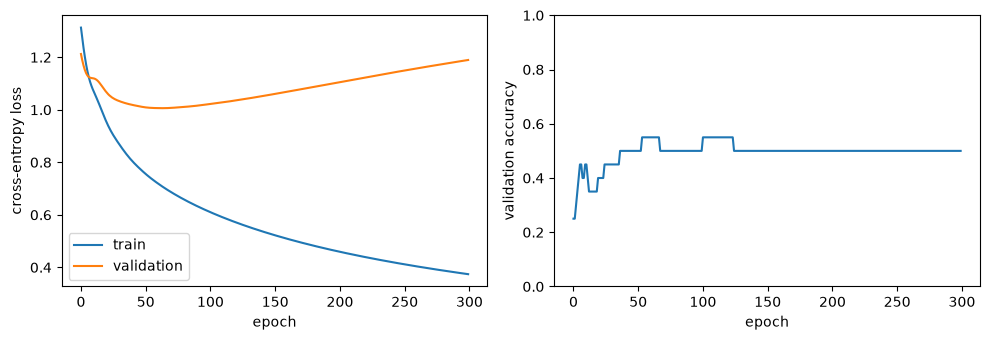

In [34]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(train_losses, label="train")
ax1.plot(val_losses, label="validation")
ax1.set_xlabel("epoch")
ax1.set_ylabel("cross-entropy loss")
ax1.legend()
ax2.plot(val_accs)
ax2.set_xlabel("epoch")
ax2.set_ylabel("validation accuracy")
ax2.set_ylim(0, 1)
plt.tight_layout()

## Predicting on the test set

Run your model on the 100 unlabelled test clips. Put your group name in the cell below before saving — the cell will not run without it.

In [35]:
test_paths = audio_files(DATA_DIR / "test")
test_files = [p.name for p in test_paths]
X_test = load_files(test_paths)
X_test.shape

(100, 64, 312)

In [36]:
Z_test = torch.tensor((embed(X_test) - mean) / std).to(device)
with torch.no_grad():
    test_preds = probe(Z_test).argmax(1).cpu().numpy()

pd.Series([classes[i] for i in test_preds]).value_counts()

European Robin    42
Eurasian Wren     32
Song Thrush       26
Name: count, dtype: int64

In [38]:
GROUP_NAME = ''

group = GROUP_NAME.strip().replace(" ", "_")
out_dir = Path("test_results")
out_dir.mkdir(exist_ok=True)
out_path = out_dir / f"{group}_autoencoder.csv"

results = pd.DataFrame({
    "filename": test_files,
    "species": [classes[i] for i in test_preds],
    "model": "autoencoder",
    "group": GROUP_NAME.strip(),
})
results.to_csv(out_path, index=False)
print(f"Saved {len(results)} predictions to {out_path}")
results.head()

Saved 100 predictions to test_results/Danny_organiser_autoencoder.csv


,filename,species,model,group
0,A4_20250306_175100_c2.wav,European Robin,autoencoder,Danny_organiser
1,A5_20250511_032600_c1.wav,Song Thrush,autoencoder,Danny_organiser
2,B5_20250317_055400_c3.wav,European Robin,autoencoder,Danny_organiser
3,C3_20250306_060300_c2.wav,Eurasian Wren,autoencoder,Danny_organiser
4,C3_20250308_074900_c11.wav,Eurasian Wren,autoencoder,Danny_organiser
